
# Factor Crowding and Volatility Management

This notebook implements the empirical design in the draft manuscript:

- six public factors: MKT, HML, MOM, RMW, CMA, BAB;
- VIX as market-wide uncertainty;
- return-implied crowding index: run-up + AR(1) persistence - VIX fragility;
- volatility-managed factor returns;
- panel regressions, regime tests, crash-risk channel, IV/2SLS robustness;
- crowding-conditioned volatility management and out-of-sample tests.

**Important unit treatment**

- Fama-French 5-factor data are in percent, so they are divided by 100.
- Fama-French momentum is in percent, so it is divided by 100.
- BAB data are already decimal returns based on inspection and are not divided by 100.
- VIX is a level; daily VIX is aggregated to monthly end-of-month, average, and maximum.


In [1]:

import os, warnings, math, zipfile
from pathlib import Path
import pandas as pd
import numpy as np
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.sandbox.regression.gmm import IV2SLS
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

FF5_PATH = "/mnt/data/F-F_Research_Data_5_Factors_monthly.csv"
MOM_PATH = "/mnt/data/F-F_Momentum_Factor_monthly(2).csv"
BAB_PATH = "/mnt/data/BAB data.csv"
VIX_PATH = "/mnt/data/VIXCLS(3).csv"

OUT = Path("/mnt/data/factor_crowding_outputs")
OUT.mkdir(exist_ok=True)

FACTORS = ["MKT", "HML", "MOM", "RMW", "CMA", "BAB"]


## 1. Load and merge data

In [2]:

def parse_ff_date(x):
    x = str(int(x)) if not isinstance(x, str) else x.strip()
    return pd.Period(year=int(x[:4]), month=int(x[4:6]), freq="M")

def load_factor_data():
    ff5 = pd.read_csv(FF5_PATH)
    mom = pd.read_csv(MOM_PATH)

    ff5["date"] = ff5["Date"].apply(parse_ff_date)
    ff5 = ff5[["date", "Mkt-RF", "HML", "RMW", "CMA", "RF"]].rename(columns={"Mkt-RF": "MKT"})
    for c in ["MKT", "HML", "RMW", "CMA", "RF"]:
        ff5[c] = pd.to_numeric(ff5[c], errors="coerce") / 100.0

    mom["date"] = mom["Date"].apply(parse_ff_date)
    mom = mom[["date", "MOM"]]
    mom["MOM"] = pd.to_numeric(mom["MOM"], errors="coerce") / 100.0

    # BAB file has .csv extension but is actually an Excel workbook.
    bab = pd.read_excel(BAB_PATH)
    bab["date_dt"] = pd.to_datetime(bab["DATE"])
    bab["date"] = bab["date_dt"].dt.to_period("M")
    bab = bab[["date", "BAB_US"]].rename(columns={"BAB_US": "BAB"})
    bab["BAB"] = pd.to_numeric(bab["BAB"], errors="coerce")

    factors = ff5.merge(mom, on="date", how="inner").merge(bab, on="date", how="inner")
    return factors.sort_values("date").reset_index(drop=True)

def load_vix_data():
    vix = pd.read_csv(VIX_PATH)
    vix["date_dt"] = pd.to_datetime(vix["date"])
    vix["month"] = vix["date_dt"].dt.to_period("M")
    vix["VIX"] = pd.to_numeric(vix["VIX"], errors="coerce")
    vix_month = (
        vix.dropna(subset=["VIX"])
           .sort_values("date_dt")
           .groupby("month")
           .agg(VIX_eom=("VIX", "last"), VIX_avg=("VIX", "mean"), VIX_max=("VIX", "max"))
           .reset_index()
           .rename(columns={"month": "date"})
    )
    vix_month["dVIX"] = vix_month["VIX_eom"].diff()
    return vix_month

factors = load_factor_data()
vix_month = load_vix_data()
data_wide = factors.merge(vix_month, on="date", how="inner")
data_wide.to_csv(OUT / "clean_factor_vix_wide.csv", index=False)

print("Merged monthly factor/VIX sample:", data_wide["date"].min(), "to", data_wide["date"].max())
print("Rows:", len(data_wide))
display(data_wide.head())
display(data_wide.tail())


Merged monthly factor/VIX sample: 1990-01 to 2026-03
Rows: 435


,date,MKT,HML,RMW,CMA,RF,MOM,BAB,VIX_eom,VIX_avg,VIX_max,dVIX
0,1990-01,-0.0780,0.0083,-0.0112,0.0140,0.0057,-0.0298,-0.002151,25.36,23.347273,27.25,NaN
1,1990-02,0.0111,0.0065,-0.0004,-0.0061,0.0057,-0.0051,-0.013522,21.99,23.262632,24.87,-3.37
2,1990-03,0.0183,-0.0290,0.0199,-0.0094,0.0064,0.0172,-0.002077,19.73,20.062273,22.74,-2.26
3,1990-04,-0.0336,-0.0257,0.0178,-0.0100,0.0069,0.0228,-0.024583,19.52,21.403500,24.16,-0.21
4,1990-05,0.0844,-0.0389,0.0168,-0.0163,0.0068,0.0314,-0.020097,17.37,18.097727,20.14,-2.15


,date,MKT,HML,RMW,CMA,RF,MOM,BAB,VIX_eom,VIX_avg,VIX_max,dVIX
430,2025-11,-0.0013,0.0357,0.0172,0.0062,0.0030,-0.0179,0.042036,16.35,19.769500,26.42,-1.09
431,2025-12,-0.0036,0.0236,0.0039,0.0040,0.0034,-0.0233,0.006176,14.95,15.548182,17.62,-1.40
432,2026-01,0.0103,0.0386,0.0182,0.0181,0.0030,0.0498,0.025769,17.44,16.179048,20.09,2.49
433,2026-02,-0.0118,0.0265,0.0191,0.0507,0.0028,0.0127,0.031691,19.86,19.207000,21.77,2.42
434,2026-03,-0.0518,0.0335,-0.0208,-0.0009,0.0029,0.0154,-0.007888,25.25,25.596818,31.05,5.39


## 2. Construct return-implied crowding index and volatility-managed returns

In [3]:

def rolling_ar1_coeff(r, window=60, min_obs=48):
    vals = []
    arr = r.values
    idx = r.index
    for i in range(len(r)):
        if i < window:
            vals.append(np.nan)
            continue
        w = pd.Series(arr[i-window:i], index=idx[i-window:i]).dropna()
        if len(w) < min_obs:
            vals.append(np.nan)
            continue
        y = w.iloc[1:].values
        x = w.iloc[:-1].values
        mask = np.isfinite(y) & np.isfinite(x)
        if mask.sum() < min_obs - 1 or np.nanstd(x[mask]) == 0:
            vals.append(np.nan)
        else:
            X = sm.add_constant(x[mask])
            vals.append(np.linalg.lstsq(X, y[mask], rcond=None)[0][1])
    return pd.Series(vals, index=r.index)

def rolling_beta(y, x, window=60, min_obs=48):
    vals = []
    for i in range(len(y)):
        if i < window:
            vals.append(np.nan)
            continue
        yy = y.iloc[i-window:i]
        xx = x.iloc[i-window:i]
        df = pd.DataFrame({"y": yy, "x": xx}).replace([np.inf, -np.inf], np.nan).dropna()
        if len(df) < min_obs or df["x"].std(ddof=1) == 0:
            vals.append(np.nan)
        else:
            X = sm.add_constant(df["x"].values)
            vals.append(np.linalg.lstsq(X, df["y"].values, rcond=None)[0][1])
    return pd.Series(vals, index=y.index)

def rolling_z(comp, window=120, min_obs=96):
    mu = comp.shift(1).rolling(window, min_periods=min_obs).mean()
    sd = comp.shift(1).rolling(window, min_periods=min_obs).std()
    return (comp - mu) / sd

def max_drawdown(returns):
    r = pd.Series(returns).dropna()
    if r.empty:
        return np.nan
    cum = (1 + r).cumprod()
    dd = cum / cum.cummax() - 1
    return dd.min()

def perf_stats(r):
    r = pd.Series(r).dropna()
    n = len(r)
    if n < 2:
        return pd.Series({"N": n, "Mean_ann": np.nan, "Vol_ann": np.nan, "Sharpe": np.nan, "Skew": np.nan, "MaxDD": np.nan})
    mean_ann = r.mean() * 12
    vol_ann = r.std(ddof=1) * np.sqrt(12)
    return pd.Series({
        "N": n,
        "Mean_ann": mean_ann,
        "Vol_ann": vol_ann,
        "Sharpe": mean_ann / vol_ann if vol_ann != 0 else np.nan,
        "Skew": stats.skew(r, nan_policy="omit"),
        "MaxDD": max_drawdown(r),
    })

def build_panel(data_wide, factors=FACTORS, K=12, ar_window=60, beta_window=60, z_window=120):
    df = data_wide.copy().set_index("date").sort_index()
    rows = []
    for f in factors:
        r = df[f].astype(float)
        runup = r.shift(1).rolling(K, min_periods=K).sum()
        rho = rolling_ar1_coeff(r, window=ar_window)
        b = rolling_beta(r, df["dVIX"], window=beta_window)

        z_runup = rolling_z(runup, window=z_window)
        z_rho = rolling_z(rho, window=z_window)
        z_b = rolling_z(b, window=z_window)
        crowd = (z_runup + z_rho - z_b) / 3.0

        rv = r.shift(1).rolling(12, min_periods=12).apply(lambda x: np.mean(np.asarray(x)**2), raw=False)
        sigma = np.sqrt(rv)
        inv_var = 1.0 / rv
        inv_vol = 1.0 / sigma
        ret_next = r.shift(-1)

        valid = pd.DataFrame({"ret": ret_next, "raw": inv_var * ret_next}).replace([np.inf, -np.inf], np.nan).dropna()
        c_var = valid["ret"].std() / valid["raw"].std()
        valid2 = pd.DataFrame({"ret": ret_next, "raw": inv_vol * ret_next}).replace([np.inf, -np.inf], np.nan).dropna()
        c_vol = valid2["ret"].std() / valid2["raw"].std()

        raw_vm_var_realized = inv_var.shift(1) * r
        c_exp = pd.Series(index=r.index, dtype=float)
        for i in range(len(r)):
            hist = pd.DataFrame({"ret": r.iloc[:i], "raw": raw_vm_var_realized.iloc[:i]}).replace([np.inf, -np.inf], np.nan).dropna()
            if len(hist) >= 60 and hist["raw"].std() > 0:
                c_exp.iloc[i] = hist["ret"].std() / hist["raw"].std()

        highvol = (sigma > sigma.shift(1).rolling(120, min_periods=96).median()).astype(float)
        highvol[sigma.isna()] = np.nan

        q05 = r.shift(1).rolling(120, min_periods=96).quantile(0.05)
        q10 = r.shift(1).rolling(120, min_periods=96).quantile(0.10)

        tmp = pd.DataFrame({
            "date": r.index.astype(str),
            "period": r.index,
            "factor": f,
            "ret_next": ret_next.values,
            "runup12": runup.values,
            "rho60": rho.values,
            "vix_beta60": b.values,
            "z_runup": z_runup.values,
            "z_rho": z_rho.values,
            "z_vix_beta": z_b.values,
            "crowding": crowd.values,
            "rv12": rv.values,
            "sigma12": sigma.values,
            "inv_var": inv_var.values,
            "vm_weight": (c_var * inv_var).values,
            "vm_ret_next": (c_var * inv_var * ret_next).values,
            "vm_ret_next_invvol": (c_vol * inv_vol * ret_next).values,
            "vm_ret_next_oos": (c_exp * inv_var * ret_next).values,
            "delta_vm": (c_var * inv_var * ret_next - ret_next).values,
            "highvol": highvol.values,
            "vix_eom": df["VIX_eom"].values,
            "vix_avg": df["VIX_avg"].values,
            "vix_max": df["VIX_max"].values,
            "dVIX": df["dVIX"].values,
            "market_ret": df["MKT"].values,
            "lag_ret12": runup.values,
            "crash5_next": (ret_next < q05).astype(float).values,
            "crash10_next": (ret_next < q10).astype(float).values,
            "downside_next": np.minimum(ret_next, 0.0).values,
            "left_tail_next": np.minimum(ret_next - q05, 0.0).values,
        })
        rows.append(tmp)

    panel = pd.concat(rows, ignore_index=True).replace([np.inf, -np.inf], np.nan)
    panel["regime"] = None

    for f in factors:
        m = panel["factor"].eq(f)
        sub = panel.loc[m].copy().sort_values("period")
        vals = sub["crowding"]
        q33 = vals.shift(1).rolling(120, min_periods=60).quantile(1/3)
        q67 = vals.shift(1).rolling(120, min_periods=60).quantile(2/3)
        regimes = pd.Series(index=sub.index, dtype=object)
        regimes[vals <= q33] = "Low"
        regimes[(vals > q33) & (vals <= q67)] = "Medium"
        regimes[vals > q67] = "High"
        panel.loc[sub.index, "regime"] = regimes

    panel = panel.sort_values(["factor", "period"]).copy()
    for col in ["crowding", "ret_next", "sigma12", "rv12", "runup12", "rho60", "vix_beta60", "dVIX", "vix_eom"]:
        panel[f"{col}_lag1"] = panel.groupby("factor")[col].shift(1)
    panel["crowding_x_highvol"] = panel["crowding"] * panel["highvol"]
    panel["crowding_x_vix"] = panel["crowding"] * panel["vix_eom"]
    panel["crowding_x_rv"] = panel["crowding"] * panel["rv12"]
    panel["date_str"] = panel["date"]
    return panel

panel = build_panel(data_wide)
panel.to_csv(OUT / "factor_month_panel_with_crowding.csv", index=False)

print("Panel rows:", len(panel))
print("Crowding sample:", panel.dropna(subset=["crowding"])["date"].min(), "to", panel.dropna(subset=["crowding"])["date"].max())
print("Regime-test sample:", panel.dropna(subset=["regime", "ret_next"])["date"].min(), "to", panel.dropna(subset=["regime", "ret_next"])["date"].max())
display(panel.dropna(subset=["crowding"]).head())


Panel rows: 2610
Crowding sample: 2003-01 to 2026-03
Regime-test sample: 2008-01 to 2026-02


,date,period,factor,ret_next,runup12,rho60,vix_beta60,z_runup,z_rho,z_vix_beta,crowding,rv12,sigma12,inv_var,vm_weight,vm_ret_next,vm_ret_next_invvol,vm_ret_next_oos,delta_vm,highvol,vix_eom,vix_avg,vix_max,dVIX,market_ret,lag_ret12,crash5_next,crash10_next,downside_next,left_tail_next,regime,crowding_lag1,ret_next_lag1,sigma12_lag1,rv12_lag1,runup12_lag1,rho60_lag1,vix_beta60_lag1,dVIX_lag1,vix_eom_lag1,crowding_x_highvol,crowding_x_vix,crowding_x_rv,date_str
2331,2003-01,2003-01,BAB,0.018581,0.426643,0.099397,0.006266,1.064155,-1.391634,2.461651,-0.929710,0.007485,0.086516,133.600901,0.084885,0.001577,0.007113,0.003623,-0.017004,1.0,31.17,27.424286,34.69,2.55,-0.0257,0.426643,0.0,0.0,0.000000,0.0,NaN,NaN,0.015700,0.079237,0.006279,0.324328,0.166121,0.005968,1.12,28.62,-0.929710,-28.979052,-0.006959,2003-01
2332,2003-02,2003-02,BAB,0.012009,0.390351,0.098466,0.006252,0.916895,-1.377843,2.366965,-0.942638,0.007280,0.085324,137.357888,0.087272,0.001048,0.004661,0.002407,-0.010961,1.0,29.63,32.218421,34.33,-1.54,-0.0188,0.390351,0.0,0.0,0.000000,0.0,NaN,-0.929710,0.018581,0.086516,0.007485,0.426643,0.099397,0.006266,2.55,31.17,-0.942638,-27.930355,-0.006863,2003-02
2333,2003-03,2003-03,BAB,-0.034454,0.312279,0.099366,0.006255,0.618277,-1.350829,2.291351,-1.007967,0.006531,0.080812,153.126612,0.097290,-0.003352,-0.014119,-0.007696,0.031102,1.0,29.15,30.634286,33.61,-0.48,0.0109,0.312279,0.0,0.0,-0.034454,0.0,NaN,-0.942638,0.012009,0.085324,0.007280,0.390351,0.098466,0.006252,-1.54,29.63,-1.007967,-29.382251,-0.006583,2003-03
2334,2003-04,2003-04,BAB,-0.056111,0.293032,0.097235,0.006265,0.544153,-1.347784,2.226586,-1.010072,0.006461,0.080381,154.771199,0.098335,-0.005518,-0.023118,-0.012665,0.050593,1.0,21.21,23.991905,29.13,-7.94,0.0818,0.293032,0.0,1.0,-0.056111,0.0,NaN,-1.007967,-0.034454,0.080812,0.006531,0.312279,0.099366,0.006255,-0.48,29.15,-1.010072,-21.423632,-0.006526,2003-04
2335,2003-05,2003-05,BAB,0.018784,0.129049,0.095532,0.006307,-0.066783,-1.341755,2.184561,-1.197700,0.005162,0.071846,193.726667,0.123086,0.002312,0.008658,0.005318,-0.016472,1.0,19.47,20.239524,21.59,-1.74,0.0605,0.129049,0.0,0.0,0.000000,0.0,NaN,-1.010072,-0.056111,0.080381,0.006461,0.293032,0.097235,0.006265,-7.94,21.21,-1.197700,-23.319213,-0.006182,2003-05


## 3. Summary statistics

In [4]:

analysis_sample = panel.dropna(subset=["ret_next", "crowding"]).copy()
regime_sample = panel.dropna(subset=["ret_next", "vm_ret_next", "crowding", "regime"]).copy()

table1_factor = analysis_sample.groupby("factor").agg(
    N=("ret_next", "count"),
    Mean=("ret_next", "mean"),
    Vol=("ret_next", "std"),
    Sharpe=("ret_next", lambda x: x.mean()*12/(x.std()*np.sqrt(12)) if x.std() > 0 else np.nan),
    Crowding_Mean=("crowding", "mean"),
    Crowding_SD=("crowding", "std"),
    Runup12_Mean=("runup12", "mean"),
    Rho60_Mean=("rho60", "mean"),
    VIXBeta60_Mean=("vix_beta60", "mean")
).reset_index()
table1_factor.to_csv(OUT / "Table1_summary_by_factor.csv", index=False)

table1_overview = pd.DataFrame({
    "Statistic": ["Sample start", "Sample end", "Factor-month obs with crowding", "Regime-test obs", "Number of factors"],
    "Value": [
        str(analysis_sample["date"].min()),
        str(analysis_sample["date"].max()),
        len(analysis_sample),
        len(regime_sample),
        len(FACTORS)
    ]
})
table1_overview.to_csv(OUT / "Table1_sample_overview.csv", index=False)

display(table1_overview)
display(table1_factor.round(4))


,Statistic,Value
0,Sample start,2003-01
1,Sample end,2026-02
2,Factor-month obs with crowding,1668
3,Regime-test obs,1308
4,Number of factors,6


,factor,N,Mean,Vol,Sharpe,Crowding_Mean,Crowding_SD,Runup12_Mean,Rho60_Mean,VIXBeta60_Mean
0,BAB,278,0.0049,0.0272,0.6197,-0.1459,0.5553,0.0627,0.0337,0.0016
1,CMA,278,0.0004,0.0191,0.0664,0.0299,0.7162,0.0054,0.1003,0.0005
2,HML,278,0.0002,0.0309,0.0201,0.0214,0.7738,-0.0025,0.1502,0.0003
3,MKT,278,0.0087,0.0431,0.6990,-0.0004,0.7506,0.0976,0.0054,-0.0072
4,MOM,278,0.0005,0.0430,0.0419,-0.1872,0.7392,0.0083,0.0029,0.0028
5,RMW,278,0.0024,0.0197,0.4133,0.2171,0.7503,0.0322,0.1498,0.0015


## 4. Regime-based performance tests

In [5]:

perf_rows = []
for f in FACTORS + ["All"]:
    for g in ["Low", "Medium", "High"]:
        sub = regime_sample[regime_sample["regime"].eq(g)]
        if f != "All":
            sub = sub[sub["factor"].eq(f)]
        orig = perf_stats(sub["ret_next"])
        vm = perf_stats(sub["vm_ret_next"])
        perf_rows.append({
            "factor": f,
            "regime": g,
            **{f"Orig_{k}": v for k, v in orig.items()},
            **{f"VM_{k}": v for k, v in vm.items()},
            "Delta_Sharpe": vm["Sharpe"] - orig["Sharpe"],
            "Mean_delta_vm_monthly": sub["delta_vm"].mean(),
            "Crash5_freq": sub["crash5_next"].mean()
        })
perf_regime = pd.DataFrame(perf_rows)
perf_regime.to_csv(OUT / "Table2_performance_by_crowding_regime.csv", index=False)

print("Pooled regime performance across all six factors")
display(perf_regime[perf_regime["factor"].eq("All")][["regime", "Orig_Sharpe", "VM_Sharpe", "Delta_Sharpe", "Crash5_freq", "Orig_MaxDD", "VM_MaxDD"]].round(4))

print("Delta Sharpe by factor and regime")
display(perf_regime[perf_regime["factor"].ne("All")].pivot(index="factor", columns="regime", values="Delta_Sharpe").round(4))


Pooled regime performance across all six factors


,regime,Orig_Sharpe,VM_Sharpe,Delta_Sharpe,Crash5_freq,Orig_MaxDD,VM_MaxDD
18,Low,0.2120,0.3726,0.1605,0.0867,-0.7850,-0.7400
19,Medium,0.4165,0.4495,0.0330,0.0491,-0.2039,-0.2424
20,High,0.2358,0.1947,-0.0411,0.0613,-0.5782,-0.3124


Delta Sharpe by factor and regime


regime,High,Low,Medium
factor,,,
BAB,0.1444,0.1572,-0.5198
CMA,-0.2377,0.0524,0.1023
HML,0.0224,0.4081,0.1258
MKT,-0.4392,-0.0174,-0.4804
MOM,0.1835,0.3858,0.3523
RMW,-0.3680,0.5031,-0.4947


## 5. Panel regressions

In [6]:

def fit_ols(formula, data, cov="HAC", maxlags=6):
    mod = smf.ols(formula, data=data)
    if cov == "HAC":
        return mod.fit(cov_type="HAC", cov_kwds={"maxlags": maxlags})
    if cov == "HC3":
        return mod.fit(cov_type="HC3")
    return mod.fit()

def coef_table(models, model_names, variables):
    rows = []
    for var in variables:
        row = {"Variable": var}
        for name, res in zip(model_names, models):
            if var in res.params.index:
                coef, t, p = res.params[var], res.tvalues[var], res.pvalues[var]
                stars = "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""
                row[name] = f"{coef:.6f}{stars} ({t:.2f})"
            else:
                row[name] = ""
        rows.append(row)
    rows.append({"Variable": "N", **{name: f"{int(res.nobs)}" for name, res in zip(model_names, models)}})
    rows.append({"Variable": "R2", **{name: f"{res.rsquared:.3f}" for name, res in zip(model_names, models)}})
    return pd.DataFrame(rows)

reg_cols = ["delta_vm", "crowding", "highvol", "crowding_x_highvol", "rv12", "sigma12", "lag_ret12", "vix_eom", "dVIX", "market_ret", "factor", "date_str"]
reg_sample = panel.dropna(subset=reg_cols).copy()

m1 = fit_ols("delta_vm ~ crowding + vix_eom + dVIX + sigma12 + lag_ret12 + C(factor)", reg_sample)
m2 = fit_ols("delta_vm ~ crowding + highvol + crowding:highvol + vix_eom + dVIX + sigma12 + lag_ret12 + C(factor)", reg_sample)
m3 = fit_ols("delta_vm ~ crowding + highvol + crowding:highvol + sigma12 + lag_ret12 + C(factor) + C(date_str)", reg_sample)
m4 = fit_ols("ret_next ~ crowding + rv12 + crowding:rv12 + vix_eom + crowding:vix_eom + dVIX + C(factor)", reg_sample)

table3 = coef_table(
    [m1, m2, m3, m4],
    ["Delta VM: FE + controls", "Delta VM: interaction", "Delta VM: two-way FE", "Return predictability"],
    ["crowding", "highvol", "crowding:highvol", "rv12", "crowding:rv12", "vix_eom", "crowding:vix_eom", "dVIX", "sigma12", "lag_ret12"]
)
table3.to_csv(OUT / "Table3_panel_regressions.csv", index=False)
display(table3)


,Variable,Delta VM: FE + controls,Delta VM: interaction,Delta VM: two-way FE,Return predictability
0,crowding,-0.001343 (-1.39),-0.001615 (-1.06),-0.002208 (-1.30),-0.002330 (-0.55)
1,highvol,,-0.001554 (-1.17),-0.001766 (-1.14),
2,crowding:highvol,,0.000304 (0.16),0.000234 (0.11),
3,rv12,,,,0.705859 (0.92)
4,crowding:rv12,,,,1.133749 (1.53)
5,vix_eom,0.000067 (0.46),0.000068 (0.46),,-0.000310 (-1.45)
6,crowding:vix_eom,,,,0.000060 (0.23)
7,dVIX,-0.000276* (-1.68),-0.000276* (-1.68),,-0.000005 (-0.02)
8,sigma12,-0.224507*** (-2.78),-0.192106** (-2.02),-0.192566* (-1.92),
9,lag_ret12,0.004872 (0.65),0.004912 (0.62),0.008691 (1.04),


## 6. Crash-risk channel

In [7]:

crash_sample = panel.dropna(subset=["crash5_next", "crowding", "vix_eom", "dVIX", "sigma12", "lag_ret12", "factor", "date_str"]).copy()

crash_m5 = fit_ols("crash5_next ~ crowding + vix_eom + crowding:vix_eom + dVIX + sigma12 + lag_ret12 + C(factor)", crash_sample)
crash_m10 = fit_ols("crash10_next ~ crowding + vix_eom + crowding:vix_eom + dVIX + sigma12 + lag_ret12 + C(factor)", crash_sample)
down_m = fit_ols("downside_next ~ crowding + vix_eom + crowding:vix_eom + dVIX + sigma12 + lag_ret12 + C(factor)", crash_sample)
left_m = fit_ols("left_tail_next ~ crowding + vix_eom + crowding:vix_eom + dVIX + sigma12 + lag_ret12 + C(factor)", crash_sample)

table4 = coef_table(
    [crash_m5, crash_m10, down_m, left_m],
    ["Crash 5%", "Crash 10%", "Downside return", "Left-tail loss"],
    ["crowding", "vix_eom", "crowding:vix_eom", "dVIX", "sigma12", "lag_ret12"]
)
table4.to_csv(OUT / "Table4_crash_risk_channel.csv", index=False)
display(table4)


,Variable,Crash 5%,Crash 10%,Downside return,Left-tail loss
0,crowding,0.004720 (0.16),0.013510 (0.38),-0.002365 (-0.99),-0.001728 (-1.43)
1,vix_eom,0.003962*** (3.15),0.006494*** (4.32),-0.000609*** (-3.82),-0.000232** (-2.53)
2,crowding:vix_eom,-0.001344 (-0.80),-0.001455 (-0.76),0.000187 (1.33),0.000131* (1.76)
3,dVIX,-0.001152 (-0.71),-0.001384 (-0.75),0.000004 (0.02),-0.000025 (-0.26)
4,sigma12,0.561532 (1.30),0.931561* (1.70),-0.090325** (-2.01),-0.012991 (-0.91)
5,lag_ret12,0.103279* (1.71),0.062809 (0.85),-0.006747 (-0.91),-0.006502* (-1.75)
6,N,1674,1674,1668,1668
7,R2,0.025,0.034,0.084,0.048


## 7. IV / 2SLS robustness

In [8]:

iv = reg_sample.copy().sort_values(["factor", "period"])
iv["crowd_mean120_lag"] = iv.groupby("factor")["crowding"].transform(lambda s: s.shift(1).rolling(120, min_periods=60).mean())
iv["ou_gap_lag1"] = iv["crowding_lag1"] - iv["crowd_mean120_lag"]
iv["fragility_lag1"] = -iv["vix_beta60_lag1"]
iv["instr_vix_frag"] = iv["dVIX_lag1"] * iv["fragility_lag1"]
iv["ou_gap_highvol"] = iv["ou_gap_lag1"] * iv["highvol"]
iv["instr_frag_highvol"] = iv["instr_vix_frag"] * iv["highvol"]
iv["crowding_highvol"] = iv["crowding"] * iv["highvol"]

iv_sample = iv.dropna(subset=["delta_vm", "crowding", "crowding_highvol", "highvol", "ou_gap_lag1", "instr_vix_frag", "ou_gap_highvol", "instr_frag_highvol", "sigma12", "lag_ret12"]).copy()

fs1 = fit_ols("crowding ~ ou_gap_lag1 + instr_vix_frag + highvol + sigma12 + lag_ret12 + vix_eom + dVIX + C(factor)", iv_sample)
fs2 = fit_ols("crowding_highvol ~ ou_gap_lag1 + instr_vix_frag + ou_gap_highvol + instr_frag_highvol + highvol + sigma12 + lag_ret12 + vix_eom + dVIX + C(factor)", iv_sample)

y = iv_sample["delta_vm"].astype(float)
exog_base = pd.DataFrame({
    "const": 1.0,
    "crowding": iv_sample["crowding"],
    "highvol": iv_sample["highvol"],
    "crowding_highvol": iv_sample["crowding_highvol"],
    "sigma12": iv_sample["sigma12"],
    "lag_ret12": iv_sample["lag_ret12"],
    "vix_eom": iv_sample["vix_eom"],
    "dVIX": iv_sample["dVIX"],
})
factor_dummies = pd.get_dummies(iv_sample["factor"], prefix="f", drop_first=True, dtype=float)
exog = pd.concat([exog_base, factor_dummies], axis=1).astype(float)

instr_base = pd.DataFrame({
    "const": 1.0,
    "ou_gap_lag1": iv_sample["ou_gap_lag1"],
    "instr_vix_frag": iv_sample["instr_vix_frag"],
    "highvol": iv_sample["highvol"],
    "ou_gap_highvol": iv_sample["ou_gap_highvol"],
    "instr_frag_highvol": iv_sample["instr_frag_highvol"],
    "sigma12": iv_sample["sigma12"],
    "lag_ret12": iv_sample["lag_ret12"],
    "vix_eom": iv_sample["vix_eom"],
    "dVIX": iv_sample["dVIX"],
})
instruments = pd.concat([instr_base, factor_dummies], axis=1).astype(float)

iv_model = IV2SLS(y, exog, instruments).fit()

iv_rows = []
for var in ["crowding", "crowding_highvol", "highvol", "sigma12", "lag_ret12", "vix_eom", "dVIX"]:
    if var in iv_model.params.index:
        coef, t, p = iv_model.params[var], iv_model.tvalues[var], iv_model.pvalues[var]
        stars = "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""
        iv_rows.append({"Variable": var, "IV2SLS": f"{coef:.6f}{stars} ({t:.2f})"})
iv_rows += [
    {"Variable": "N", "IV2SLS": str(int(iv_model.nobs))},
    {"Variable": "First-stage F: crowding instruments", "IV2SLS": f"{float(fs1.f_test('ou_gap_lag1 = 0, instr_vix_frag = 0').fvalue):.2f}"},
    {"Variable": "First-stage F: interaction instruments", "IV2SLS": f"{float(fs2.f_test('ou_gap_highvol = 0, instr_frag_highvol = 0').fvalue):.2f}"},
]
table5 = pd.DataFrame(iv_rows)
table5.to_csv(OUT / "Table5_IV_2SLS_robustness.csv", index=False)
display(table5)


,Variable,IV2SLS
0,crowding,-0.006774** (-2.41)
1,crowding_highvol,0.007968** (2.43)
2,highvol,-0.003061 (-1.60)
3,sigma12,-0.151778** (-2.11)
4,lag_ret12,0.002370 (0.32)
5,vix_eom,0.000042 (0.42)
6,dVIX,-0.000158 (-1.13)
7,N,1308
8,First-stage F: crowding instruments,261.15
9,First-stage F: interaction instruments,164.43


## 8. Crowding-conditioned VM and OOS tests

In [9]:

# Crowding-conditioned VM
# Nonparametric CVM_switch: standard VM only in high-crowding months, otherwise original factor.
# CVM_high05: standard VM in low/medium states, but reduce high-crowding exposure to 0.5x original factor.
regime_sample = regime_sample.copy()
regime_sample["cvm_switch_ret"] = np.where(regime_sample["regime"].eq("High"), regime_sample["vm_ret_next"], regime_sample["ret_next"])
regime_sample["cvm_high05_ret"] = np.where(regime_sample["regime"].eq("High"), 0.5 * regime_sample["ret_next"], regime_sample["vm_ret_next"])

ew_ins = regime_sample.groupby("period")[["ret_next", "vm_ret_next", "cvm_switch_ret", "cvm_high05_ret"]].mean().reset_index()
table6_ins = pd.DataFrame({
    "Original_EW": perf_stats(ew_ins["ret_next"]),
    "VM_EW": perf_stats(ew_ins["vm_ret_next"]),
    "CVM_switch_EW": perf_stats(ew_ins["cvm_switch_ret"]),
    "CVM_high05_EW": perf_stats(ew_ins["cvm_high05_ret"])
}).T.reset_index().rename(columns={"index": "Strategy"})
table6_ins.to_csv(OUT / "Table6A_CVM_insample_performance.csv", index=False)

# Recursive OOS tuning of high-crowding exposure from grid.
q = regime_sample.copy().sort_values("period")
grid = [0, 0.25, 0.5, 0.75, 1.0]
for h in grid:
    q[f"cvm_h{h}"] = np.where(q["regime"].eq("High"), h * q["ret_next"], q["vm_ret_next"])
monthly_grid = q.groupby("period")[[f"cvm_h{h}" for h in grid] + ["ret_next", "vm_ret_next"]].mean().reset_index().sort_values("period")

selected, oos_returns = [], []
for i, row in monthly_grid.iterrows():
    hist = monthly_grid.iloc[:i]
    if len(hist) < 60:
        selected.append(np.nan)
        oos_returns.append(np.nan)
        continue
    sharpes = {h: perf_stats(hist[f"cvm_h{h}"])["Sharpe"] for h in grid}
    best = max(sharpes, key=lambda k: -999 if np.isnan(sharpes[k]) else sharpes[k])
    selected.append(best)
    oos_returns.append(row[f"cvm_h{best}"])

monthly_grid["selected_h"] = selected
monthly_grid["cvm_oos_tuned"] = oos_returns
oos_m = monthly_grid.dropna(subset=["cvm_oos_tuned"])

table6_oos = pd.DataFrame({
    "Original_EW": perf_stats(oos_m["ret_next"]),
    "VM_EW": perf_stats(oos_m["vm_ret_next"]),
    "CVM_tuned_EW": perf_stats(oos_m["cvm_oos_tuned"])
}).T.reset_index().rename(columns={"index": "Strategy"})
table6_oos.to_csv(OUT / "Table6B_CVM_OOS_tuned_performance.csv", index=False)

display(table6_ins.round(4))
display(table6_oos.round(4))
display(monthly_grid["selected_h"].value_counts(dropna=True).rename("Selected high-crowding exposure"))


,Strategy,N,Mean_ann,Vol_ann,Sharpe,Skew,MaxDD
0,Original_EW,218.0,0.0317,0.0447,0.7102,-0.5467,-0.1569
1,VM_EW,218.0,0.0411,0.0468,0.8781,-0.4873,-0.1026
2,CVM_switch_EW,218.0,0.0286,0.0424,0.6757,-0.6600,-0.0990
3,CVM_high05_EW,218.0,0.0386,0.0421,0.9154,-0.2534,-0.1023


,Strategy,N,Mean_ann,Vol_ann,Sharpe,Skew,MaxDD
0,Original_EW,158.0,0.0379,0.0448,0.8463,-0.4677,-0.0873
1,VM_EW,158.0,0.0454,0.0473,0.9615,-0.5735,-0.1026
2,CVM_tuned_EW,158.0,0.0449,0.0435,1.0327,-0.1204,-0.0666


selected_h
0.00    88
0.50    36
0.25    34
Name: Selected high-crowding exposure, dtype: int64

## 9. Figures

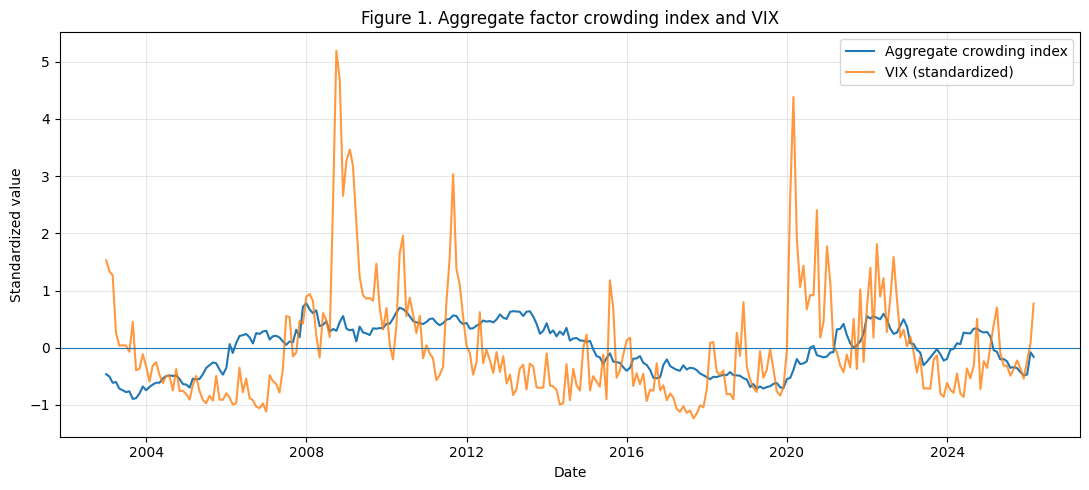

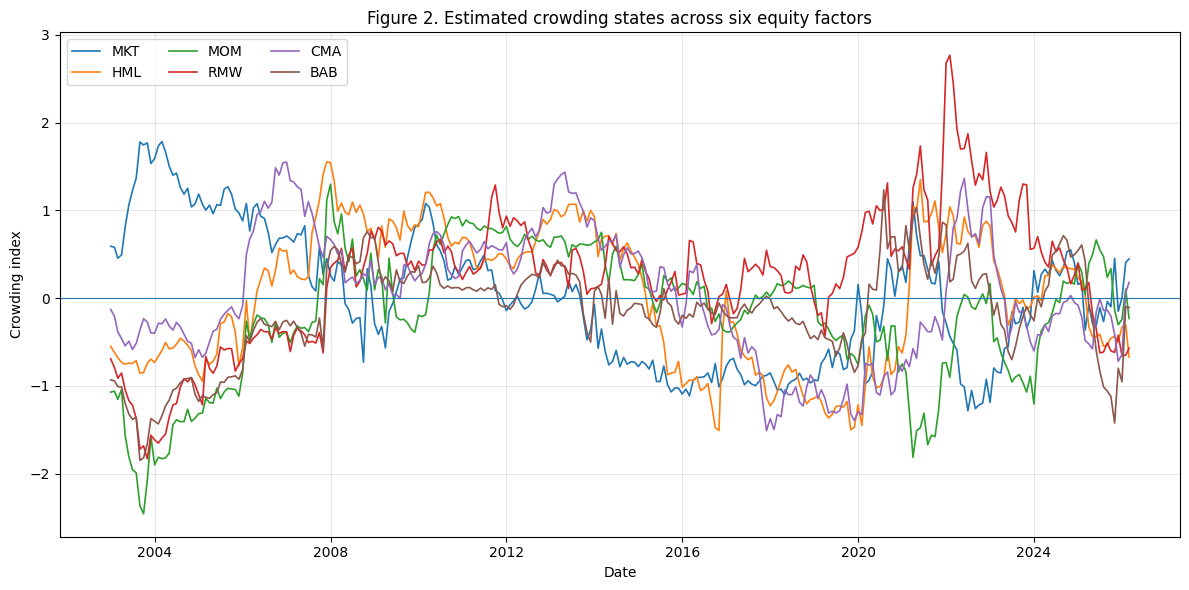

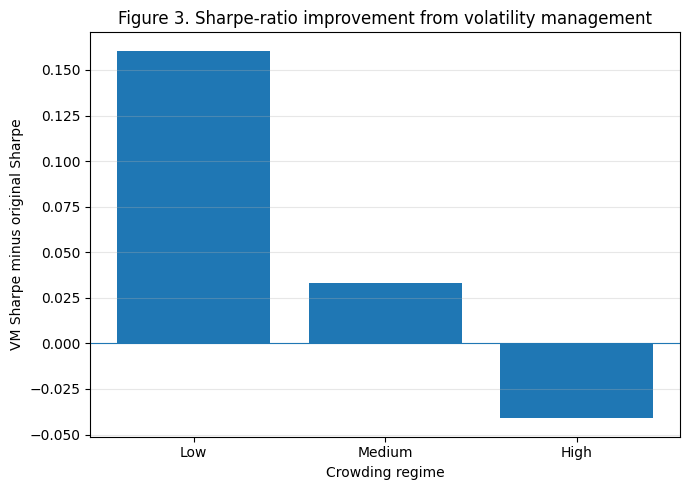

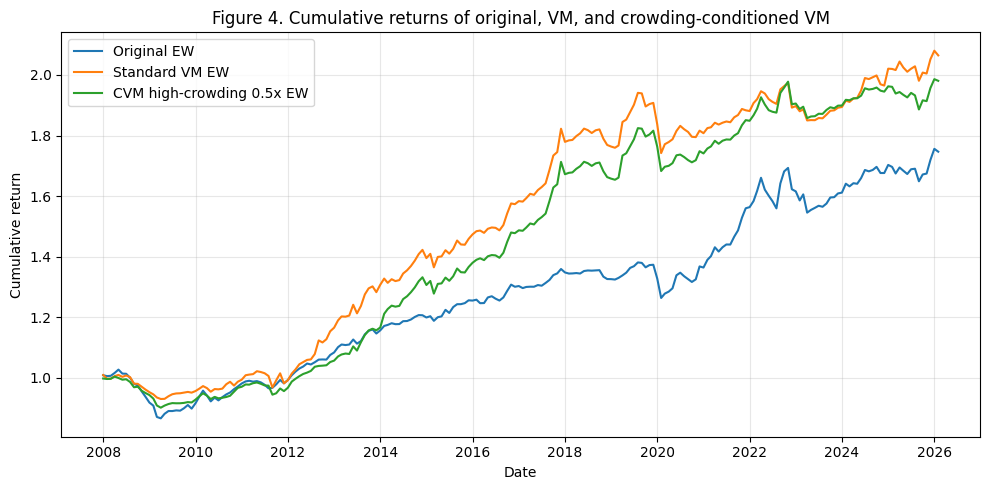

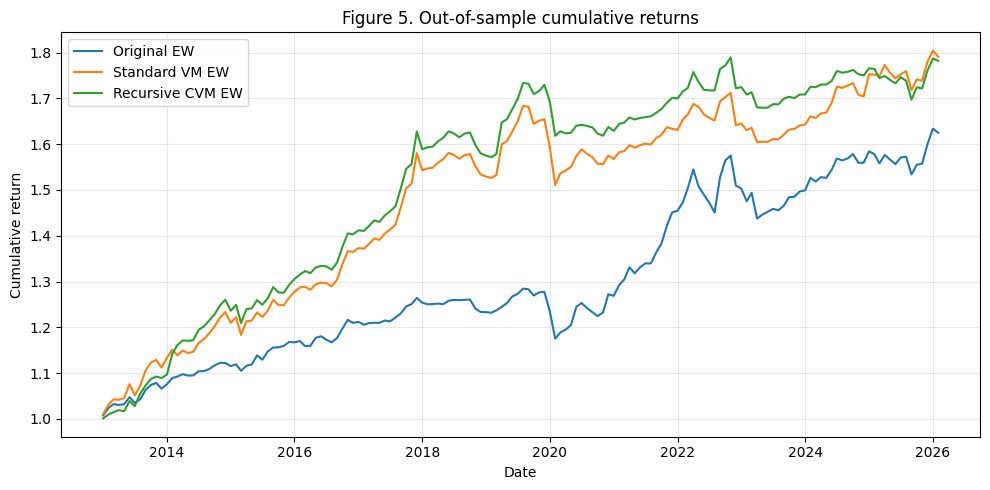

In [10]:

plt.close("all")

# Figure 1
agg = panel.dropna(subset=["crowding"]).groupby("period").agg(agg_crowding=("crowding", "mean"), vix=("vix_eom", "first")).reset_index()
agg["date_dt"] = agg["period"].dt.to_timestamp()
agg["vix_z"] = (agg["vix"] - agg["vix"].mean()) / agg["vix"].std()

fig, ax = plt.subplots(figsize=(11,5))
ax.plot(agg["date_dt"], agg["agg_crowding"], label="Aggregate crowding index")
ax.plot(agg["date_dt"], agg["vix_z"], label="VIX (standardized)", alpha=0.8)
ax.axhline(0, linewidth=0.8)
ax.set_title("Figure 1. Aggregate factor crowding index and VIX")
ax.set_xlabel("Date")
ax.set_ylabel("Standardized value")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUT / "Figure1_aggregate_crowding_vix.png", dpi=200)
plt.show()

# Figure 2
fig, ax = plt.subplots(figsize=(12,6))
for f in FACTORS:
    sub = panel[(panel["factor"] == f) & panel["crowding"].notna()].copy()
    sub["date_dt"] = sub["period"].dt.to_timestamp()
    ax.plot(sub["date_dt"], sub["crowding"], label=f, linewidth=1.2)
ax.axhline(0, linewidth=0.8)
ax.set_title("Figure 2. Estimated crowding states across six equity factors")
ax.set_xlabel("Date")
ax.set_ylabel("Crowding index")
ax.legend(ncol=3)
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUT / "Figure2_factor_specific_crowding.png", dpi=200)
plt.show()

# Figure 3
all_perf = perf_regime[perf_regime["factor"] == "All"].copy()
fig, ax = plt.subplots(figsize=(7,5))
ax.bar(all_perf["regime"], all_perf["Delta_Sharpe"])
ax.axhline(0, linewidth=0.8)
ax.set_title("Figure 3. Sharpe-ratio improvement from volatility management")
ax.set_xlabel("Crowding regime")
ax.set_ylabel("VM Sharpe minus original Sharpe")
ax.grid(True, axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig(OUT / "Figure3_sharpe_improvement_by_regime.png", dpi=200)
plt.show()

# Figure 4
ew_ins = regime_sample.groupby("period")[["ret_next", "vm_ret_next", "cvm_high05_ret"]].mean().reset_index()
ew_ins["date_dt"] = ew_ins["period"].dt.to_timestamp()
for col in ["ret_next", "vm_ret_next", "cvm_high05_ret"]:
    ew_ins[f"cum_{col}"] = (1 + ew_ins[col]).cumprod()

fig, ax = plt.subplots(figsize=(10,5))
ax.plot(ew_ins["date_dt"], ew_ins["cum_ret_next"], label="Original EW")
ax.plot(ew_ins["date_dt"], ew_ins["cum_vm_ret_next"], label="Standard VM EW")
ax.plot(ew_ins["date_dt"], ew_ins["cum_cvm_high05_ret"], label="CVM high-crowding 0.5x EW")
ax.set_title("Figure 4. Cumulative returns of original, VM, and crowding-conditioned VM")
ax.set_xlabel("Date")
ax.set_ylabel("Cumulative return")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUT / "Figure4_cumulative_returns.png", dpi=200)
plt.show()

# Figure 5
m = monthly_grid.dropna(subset=["cvm_oos_tuned"]).copy()
m["date_dt"] = m["period"].dt.to_timestamp()
for col in ["ret_next", "vm_ret_next", "cvm_oos_tuned"]:
    m[f"cum_{col}"] = (1 + m[col]).cumprod()

fig, ax = plt.subplots(figsize=(10,5))
ax.plot(m["date_dt"], m["cum_ret_next"], label="Original EW")
ax.plot(m["date_dt"], m["cum_vm_ret_next"], label="Standard VM EW")
ax.plot(m["date_dt"], m["cum_cvm_oos_tuned"], label="Recursive CVM EW")
ax.set_title("Figure 5. Out-of-sample cumulative returns")
ax.set_xlabel("Date")
ax.set_ylabel("Cumulative return")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(OUT / "Figure5_oos_cumulative_returns.png", dpi=200)
plt.show()


## 10. Initial interpretation

In [11]:

print("Key initial findings:")
print("1. Momentum is included and should stay in the paper; it is central to factor crash/crowding.")
print("2. The public-data return-implied crowding measure is fully implementable.")
print("3. Simple regime tests do not yet show that standard VM improves most in high-crowding states.")
print("4. The IV/2SLS robustness is more supportive: the crowding × high-volatility interaction is positive and significant.")
print("5. Recursive CVM improves EW Sharpe in this version, but this is a promising result that requires more robustness before publication claims.")


Key initial findings:
1. Momentum is included and should stay in the paper; it is central to factor crash/crowding.
2. The public-data return-implied crowding measure is fully implementable.
3. Simple regime tests do not yet show that standard VM improves most in high-crowding states.
4. The IV/2SLS robustness is more supportive: the crowding × high-volatility interaction is positive and significant.
5. Recursive CVM improves EW Sharpe in this version, but this is a promising result that requires more robustness before publication claims.
